In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

In [2]:
df = pd.read_csv("boxes_by_seq.csv")
df.shape

(436797, 12)

In [3]:
df.head()

,seq_name,frame_n,track_id,frame_h,frame_w,altitude,x_left,y_top,width,height,pos_x,pos_y
0,PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_150928411...,151,1,960,1280,660,415,61,17,14,465,145
1,PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_150928411...,152,1,960,1280,660,414,58,22,15,465,144
2,PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_150928411...,153,1,960,1280,660,415,53,22,20,467,144
3,PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_150928411...,154,1,960,1280,660,415,52,25,21,468,145
4,PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_150928411...,155,1,960,1280,660,414,50,25,22,470,145


In [4]:
df = df[df["altitude"] != "NODATA"]
df["altitude"] = pd.to_numeric(df["altitude"])

df = df[(df["width"] > 0) & (df["height"] > 0)]

df["pos_x_rel"] = df["pos_x"] / df["frame_w"]
df["pos_y_rel"] = df["pos_y"] / df["frame_h"]

df["x_left_rel"] = df["x_left"] / df["frame_w"]
df["y_top_rel"] = df["y_top"] / df["frame_h"]

df["width_rel"] = df["width"] / df["frame_w"]
df["height_rel"] = df["height"] / df["frame_h"]

df["frame_ratio"] = df["frame_h"] / df["frame_w"]
df["box_ratio"] = df["height"] / df["width"]
df["box_center_x_rel"] = df["x_left_rel"] + df["width_rel"] / 2
df["box_center_y_rel"] = df["y_top_rel"] + df["height_rel"] / 2

In [18]:
names = df["seq_name"].unique()

In [19]:
names[0]

'PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_1509284114.avi.seq'

In [20]:
tmp_df = df[df["seq_name"] == names[0]]

In [21]:
track_ids = tmp_df["track_id"].unique()

In [22]:
track0 = df[df["track_id"] == track_ids[0]][["pos_x", "pos_y"]].values

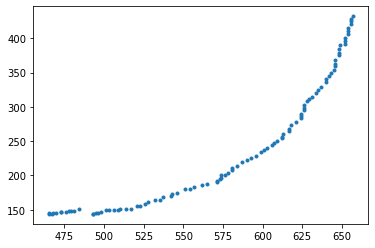

In [23]:
plt.plot(*track0[:100].T, '.')

(0.0, 1.0)

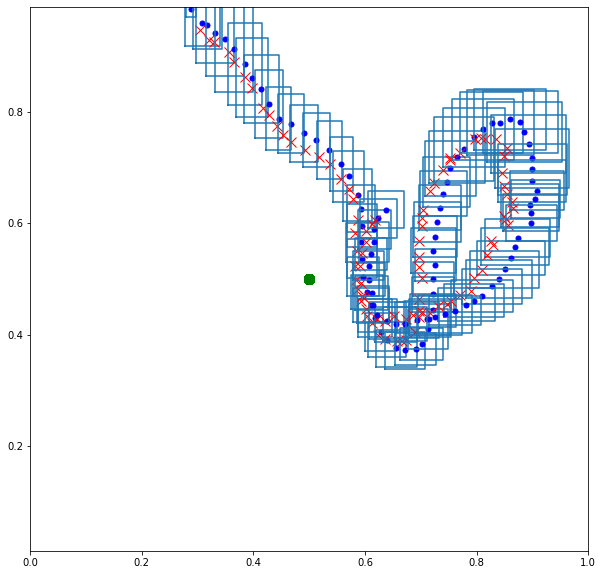

In [26]:
idx = 125
plt.figure(figsize=(10, 10))
plt.axis("equal")
for idx in np.arange(0, 900, 10):
    x, y, w, h, pos_x, pos_y, center_x, center_y = df[(df["seq_name"] == names[2]) & (df["track_id"] == 1)].iloc[idx][[
        "x_left_rel", "y_top_rel", "width_rel", "height_rel", "pos_x_rel", "pos_y_rel", "box_center_x_rel", "box_center_y_rel"]].values

    

    plt.plot(0.5, 0.5, 'go', markersize=10)
    plt.plot(*np.array([
        [x, y],
        [x, y + h],
        [x + w, y + h],
        [x + w, y],
        [x, y]
    ]).T, c="tab:blue")
    plt.plot(center_x, center_y, 'bo', markersize=5)

    plt.plot(pos_x, pos_y, 'rx', markersize=10)

plt.xlim(0, 1)
plt.ylim(0, 1)

In [ ]:
idx = 125
plt.figure(figsize=(10, 10))
plt.axis("equal")
for idx in np.arange(5504, 5510):
    x, y, w, h, pos_x, pos_y, center_x, center_y = df.iloc[idx][[
        "x_left_rel", "y_top_rel", "width_rel", "height_rel", "pos_x_rel", "pos_y_rel", "box_center_x_rel", "box_center_y_rel"]].values

    

    plt.plot(0.5, 0.5, 'go', markersize=10)
    plt.plot(*np.array([
        [x, y],
        [x, y + h],
        [x + w, y + h],
        [x + w, y],
        [x, y]
    ]).T, c="tab:blue")
    plt.plot(center_x, center_y, 'bo', markersize=5)

    plt.plot(pos_x, pos_y, 'rx', markersize=10)

plt.xlim(0, 1)
plt.ylim(0, 1)

In [80]:
X_train, X_test, y_train, y_test = train_test_split(
    df[["box_center_x_rel", "box_center_y_rel", "box_ratio", "frame_ratio"]].values, df[["pos_x_rel", "pos_y_rel"]].values, test_size=0.1, random_state=42)

In [81]:
pipe = Pipeline([
    ("preprocess", StandardScaler()),
    ("model", Ridge())
])

params = {
    "model__alpha": [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 1.5, 2, 5, 10, 20, 50],
}

model_x = GridSearchCV(pipe, params)
model_x.fit(X_train, y_train[:, 0])

model_y = GridSearchCV(pipe, params)
model_y.fit(X_train, y_train[:, 1])

GridSearchCV(estimator=Pipeline(steps=[('preprocess', StandardScaler()),
                                       ('model', Ridge())]),
             param_grid={'model__alpha': [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1,
                                          1.5, 2, 5, 10, 20, 50]})

In [82]:
model_x.score(X_test, y_test[:, 0]), model_y.score(X_test, y_test[:, 1])

(0.9815493723712633, 0.9814119163378774)

In [83]:
pred_x = model_x.predict(X_test)
pred_y = model_y.predict(X_test)

mean_squared_error(y_test[:, 0], pred_x), mean_squared_error(y_test[:, 1], pred_y)

(0.0005277258408434972, 0.0007686532141223759)

In [84]:
mean_absolute_error(y_test[:, 0], pred_x), mean_absolute_error(y_test[:, 1], pred_y)

(0.01608014010507374, 0.019861650006895964)

In [85]:
mean_squared_error(X_test[:, 0], y_test[:, 0]), mean_squared_error(X_test[:, 1], y_test[:, 1])

(0.0016426623592446573, 0.001771890350701996)

In [86]:
mean_absolute_error(X_test[:, 0], y_test[:, 0]), mean_absolute_error(X_test[:, 1], y_test[:, 1])

(0.02682398086939103, 0.03000995640644078)

(0.0, 1.0)

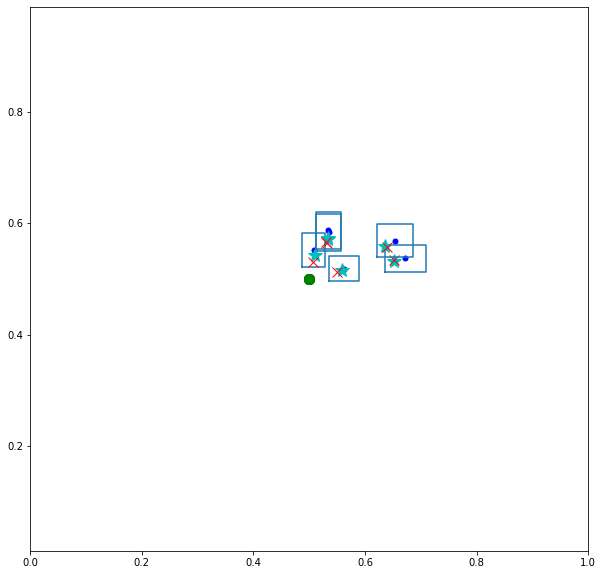

In [87]:
idx = 125
plt.figure(figsize=(10, 10))
plt.axis("equal")
for idx in np.arange(2504, 2510):
    x, y, w, h, pos_x, pos_y, center_x, center_y, box_ratio, frame_ratio = df.iloc[idx][[
        "x_left_rel", "y_top_rel",
        "width_rel", "height_rel",
        "pos_x_rel", "pos_y_rel",
        "box_center_x_rel", "box_center_y_rel",
        "box_ratio", "frame_ratio"
    ]].values

    pred_x = model_x.predict([[center_x, center_y, box_ratio, frame_ratio]])
    pred_y = model_y.predict([[center_x, center_y, box_ratio, frame_ratio]])

    plt.plot(0.5, 0.5, 'go', markersize=10)
    plt.plot(*np.array([
        [x, y],
        [x, y + h],
        [x + w, y + h],
        [x + w, y],
        [x, y]
    ]).T, c="tab:blue")
    plt.plot(center_x, center_y, 'bo', markersize=5)
    
    plt.plot(pred_x, pred_y, 'c*', markersize=15)
    plt.plot(pos_x, pos_y, 'rx', markersize=10)
    
    

plt.xlim(0, 1)
plt.ylim(0, 1)

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    df[["box_center_x_rel", "box_center_y_rel", "box_ratio", "frame_ratio"]].values, df[["pos_x_rel", "pos_y_rel"]].values, test_size=0.1, random_state=42)

pipe = Pipeline([
    ("preprocess", StandardScaler()),
    ("model", RandomForestRegressor())
])

params = {
    'model__n_estimators': np.arange(5, 26, 5),
    'model__max_depth': [1, 2, 3, 4, 5],
}

model_x = GridSearchCV(pipe, params)
model_x.fit(X_train, y_train[:, 0])

model_y = GridSearchCV(pipe, params)
model_y.fit(X_train, y_train[:, 1])

print("scores", model_x.score(X_test, y_test[:, 0]), model_y.score(X_test, y_test[:, 1]))

pred_x = model_x.predict(X_test)
pred_y = model_y.predict(X_test)

print("mse", mean_squared_error(y_test[:, 0], pred_x), mean_squared_error(y_test[:, 1], pred_y))
print("mae", mean_absolute_error(y_test[:, 0], pred_x), mean_absolute_error(y_test[:, 1], pred_y))

scores 0.9897387151730908 0.9866869067883127
mse 0.0002934938188759099 0.0005505221556499959
mae 0.010739512918988186 0.015568481772815371


(0.0, 1.0)

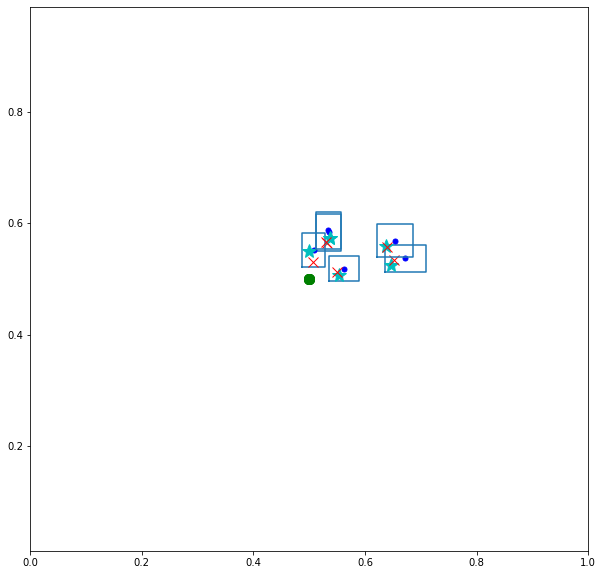

In [16]:
idx = 125
plt.figure(figsize=(10, 10))
plt.axis("equal")
for idx in np.arange(2504, 2510):
    x, y, w, h, pos_x, pos_y, center_x, center_y, box_ratio, frame_ratio = df.iloc[idx][[
        "x_left_rel", "y_top_rel",
        "width_rel", "height_rel",
        "pos_x_rel", "pos_y_rel",
        "box_center_x_rel", "box_center_y_rel",
        "box_ratio", "frame_ratio"
    ]].values

    pred_x = model_x.predict([[center_x, center_y, box_ratio, frame_ratio]])
    pred_y = model_y.predict([[center_x, center_y, box_ratio, frame_ratio]])

    plt.plot(0.5, 0.5, 'go', markersize=10)
    plt.plot(*np.array([
        [x, y],
        [x, y + h],
        [x + w, y + h],
        [x + w, y],
        [x, y]
    ]).T, c="tab:blue")
    plt.plot(center_x, center_y, 'bo', markersize=5)
    
    plt.plot(pred_x, pred_y, 'c*', markersize=15)
    plt.plot(pos_x, pos_y, 'rx', markersize=10)
    
    

plt.xlim(0, 1)
plt.ylim(0, 1)

scores 0.9882929323822809 0.9870051168645718
mse 0.00033484617578808827 0.000537363553486984
mae 0.012178032966135389 0.016628176565814033


(0.0, 1.0)

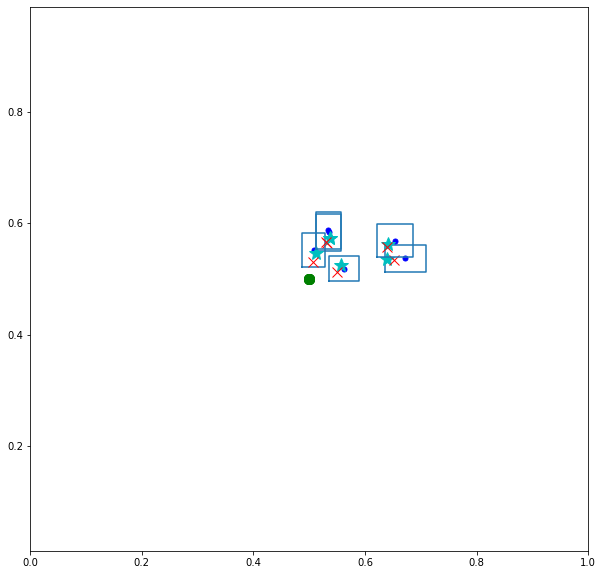

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    df[["box_center_x_rel", "box_center_y_rel", "box_ratio", "frame_ratio"]].values, df[["pos_x_rel", "pos_y_rel"]].values, test_size=0.1, random_state=42)

pipe = Pipeline([
    ("preprocess", StandardScaler()),
    ("model", MLPRegressor())
])

params = {
    'model__hidden_layer_sizes': [(10,), (10, 5), (10, 5, 3), (5, 10, 3)],
    'model__max_iter': [50, 100, 150],
    'model__activation': ['relu'],
    'model__solver': ['adam'],
    'model__alpha': [0.0001, 0.05],
    'model__learning_rate': ['constant','adaptive'],
}

model_x = GridSearchCV(pipe, params)
model_x.fit(X_train, y_train[:, 0])

model_y = GridSearchCV(pipe, params)
model_y.fit(X_train, y_train[:, 1])

print("scores", model_x.score(X_test, y_test[:, 0]), model_y.score(X_test, y_test[:, 1]))

pred_x = model_x.predict(X_test)
pred_y = model_y.predict(X_test)

print("mse", mean_squared_error(y_test[:, 0], pred_x), mean_squared_error(y_test[:, 1], pred_y))
print("mae", mean_absolute_error(y_test[:, 0], pred_x), mean_absolute_error(y_test[:, 1], pred_y))

idx = 125
plt.figure(figsize=(10, 10))
plt.axis("equal")
for idx in np.arange(2504, 2510):
    x, y, w, h, pos_x, pos_y, center_x, center_y, box_ratio, frame_ratio = df.iloc[idx][[
        "x_left_rel", "y_top_rel",
        "width_rel", "height_rel",
        "pos_x_rel", "pos_y_rel",
        "box_center_x_rel", "box_center_y_rel",
        "box_ratio", "frame_ratio"
    ]].values

    pred_x = model_x.predict([[center_x, center_y, box_ratio, frame_ratio]])
    pred_y = model_y.predict([[center_x, center_y, box_ratio, frame_ratio]])

    plt.plot(0.5, 0.5, 'go', markersize=10)
    plt.plot(*np.array([
        [x, y],
        [x, y + h],
        [x + w, y + h],
        [x + w, y],
        [x, y]
    ]).T, c="tab:blue")
    plt.plot(center_x, center_y, 'bo', markersize=5)
    
    plt.plot(pred_x, pred_y, 'c*', markersize=15)
    plt.plot(pos_x, pos_y, 'rx', markersize=10)
    
    

plt.xlim(0, 1)
plt.ylim(0, 1)

scores 0.9815493723556971 0.981411916430876
mse 0.0005277258412887254 0.0007686532102767073
mae 0.01608013874162234 0.019861651085979492


(0.0, 1.0)

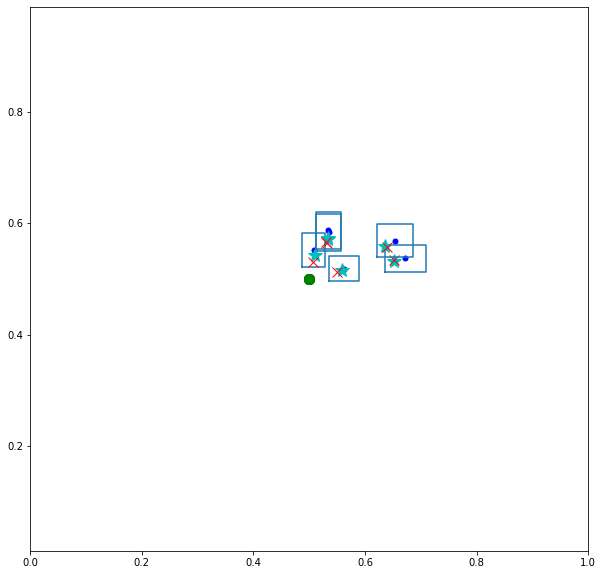

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    df[["box_center_x_rel", "box_center_y_rel", "box_ratio", "frame_ratio"]].values, df[["pos_x_rel", "pos_y_rel"]].values, test_size=0.1, random_state=42)

params = {
    "alpha": [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 1.5, 2, 5, 10, 20, 50],
}

model_x = GridSearchCV(Ridge(), params)
model_x.fit(X_train, y_train[:, 0])

model_y = GridSearchCV(Ridge(), params)

model_y.fit(X_train, y_train[:, 1])

print("scores", model_x.score(X_test, y_test[:, 0]), model_y.score(X_test, y_test[:, 1]))

pred_x = model_x.predict(X_test)
pred_y = model_y.predict(X_test)

print("mse", mean_squared_error(y_test[:, 0], pred_x), mean_squared_error(y_test[:, 1], pred_y))
print("mae", mean_absolute_error(y_test[:, 0], pred_x), mean_absolute_error(y_test[:, 1], pred_y))

idx = 125
plt.figure(figsize=(10, 10))
plt.axis("equal")
for idx in np.arange(2504, 2510):
    x, y, w, h, pos_x, pos_y, center_x, center_y, box_ratio, frame_ratio = df.iloc[idx][[
        "x_left_rel", "y_top_rel",
        "width_rel", "height_rel",
        "pos_x_rel", "pos_y_rel",
        "box_center_x_rel", "box_center_y_rel",
        "box_ratio", "frame_ratio"
    ]].values

    pred_x = model_x.predict([[center_x, center_y, box_ratio, frame_ratio]])
    pred_y = model_y.predict([[center_x, center_y, box_ratio, frame_ratio]])

    plt.plot(0.5, 0.5, 'go', markersize=10)
    plt.plot(*np.array([
        [x, y],
        [x, y + h],
        [x + w, y + h],
        [x + w, y],
        [x, y]
    ]).T, c="tab:blue")
    plt.plot(center_x, center_y, 'bo', markersize=5)
    
    plt.plot(pred_x, pred_y, 'c*', markersize=15)
    plt.plot(pos_x, pos_y, 'rx', markersize=10)
    
    

plt.xlim(0, 1)
plt.ylim(0, 1)

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    df[["box_center_x_rel", "box_center_y_rel", "box_ratio", "frame_ratio"]].values, df[["pos_x_rel", "pos_y_rel"]].values, test_size=0.1, random_state=42)

params = {
    'n_estimators': np.arange(5, 26, 5),
    'max_depth': [1, 2, 3, 4, 5],
}

model_x = GridSearchCV(RandomForestRegressor(), params)
model_x.fit(X_train, y_train[:, 0])

model_y = GridSearchCV(RandomForestRegressor(), params)
model_y.fit(X_train, y_train[:, 1])

print("scores", model_x.score(X_test, y_test[:, 0]), model_y.score(X_test, y_test[:, 1]))

pred_x = model_x.predict(X_test)
pred_y = model_y.predict(X_test)

print("mse", mean_squared_error(y_test[:, 0], pred_x), mean_squared_error(y_test[:, 1], pred_y))
print("mae", mean_absolute_error(y_test[:, 0], pred_x), mean_absolute_error(y_test[:, 1], pred_y))

scores 0.9897952929362467 0.9866619645713944
mse 0.00029187557866016794 0.0005515535645649817
mae 0.010629061835018754 0.015560489180553597
